import csv and check the head of the dataframe 

In [2]:
import matplotlib.pyplot as plt 
import pandas as pd 

df = pd.read_csv("/Users/hayansaab/Desktop/research/Sparkov_Data_Generation/output_data/transactions.csv", sep= '|')
print(df.head())



           ssn            cc_num first    last gender            street  \
0  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
1  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
2  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
3  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
4  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   

          city state    zip      lat  ...   unix_time      category     amt  \
0  Santa Clara    CA  95050  37.3492  ...  1755907145      misc_pos   69.25   
1  Santa Clara    CA  95050  37.3492  ...  1740759511   food_dining   98.36   
2  Santa Clara    CA  95050  37.3492  ...  1752252307  shopping_net  336.53   
3  Santa Clara    CA  95050  37.3492  ...  1754140703  shopping_net   96.74   
4  Santa Clara    CA  95050  37.3492  ...  1748656010  shopping_pos   59.19   

  is_fraud             merchant  merch_lat  merch_long   mcc merchant_size

In [3]:
print(df.shape)

(83992, 32)


In [5]:
pd.set_option('display.max_columns', None)
print(df.head())

           ssn            cc_num first    last gender            street  \
0  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
1  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
2  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
3  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
4  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   

          city state    zip      lat     long  city_pop      job         dob  \
0  Santa Clara    CA  95050  37.3492 -121.953    115820  Teacher  1961-06-12   
1  Santa Clara    CA  95050  37.3492 -121.953    115820  Teacher  1961-06-12   
2  Santa Clara    CA  95050  37.3492 -121.953    115820  Teacher  1961-06-12   
3  Santa Clara    CA  95050  37.3492 -121.953    115820  Teacher  1961-06-12   
4  Santa Clara    CA  95050  37.3492 -121.953    115820  Teacher  1961-06-12   

      acct_num                      profile income_band     educatio

In [11]:
print(df['trans_date'].dtype)


datetime64[ns]


In [ ]:
df['trans_date'] = pd.to_datetime(df['trans_date'])

           ssn            cc_num first    last gender            street  \
0  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
1  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
2  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
3  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   
4  271-06-7528  5283276483503056   Ian  Cooper      M  1849 Ray Squares   

          city state    zip      lat     long  city_pop      job         dob  \
0  Santa Clara    CA  95050  37.3492 -121.953    115820  Teacher  1961-06-12   
1  Santa Clara    CA  95050  37.3492 -121.953    115820  Teacher  1961-06-12   
2  Santa Clara    CA  95050  37.3492 -121.953    115820  Teacher  1961-06-12   
3  Santa Clara    CA  95050  37.3492 -121.953    115820  Teacher  1961-06-12   
4  Santa Clara    CA  95050  37.3492 -121.953    115820  Teacher  1961-06-12   

      acct_num income_band     education marital_status trans_date t

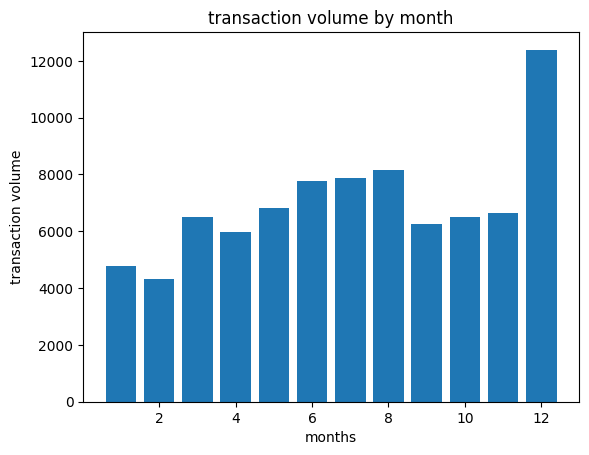

In [22]:
new = df.drop(columns = ['profile', 'trans_num',])
print(new.head())
months = new['trans_date'].dt.month
months_matrix = months.value_counts().sort_index()

plt.bar(months_matrix.index, months_matrix.values)
plt.xlabel('months')
plt.ylabel('transaction volume')
plt.title("transaction volume by month")
plt.show()

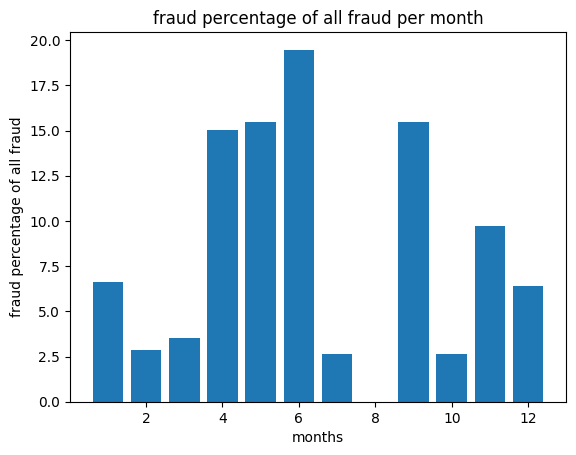

In [ ]:
total_fraud = (new['is_fraud']==1).sum()
fraud_df = new.loc[new['is_fraud'] == 1, 'trans_date']
fraud_counts = fraud_df.dt.month.value_counts().sort_index()
plt.bar(fraud_counts.index, fraud_counts.values/total_fraud * 100)

plt.xlabel('months')
plt.ylabel('fraud percentage of all fraud')
plt.title('fraud percentage of all fraud per month')
plt.show()

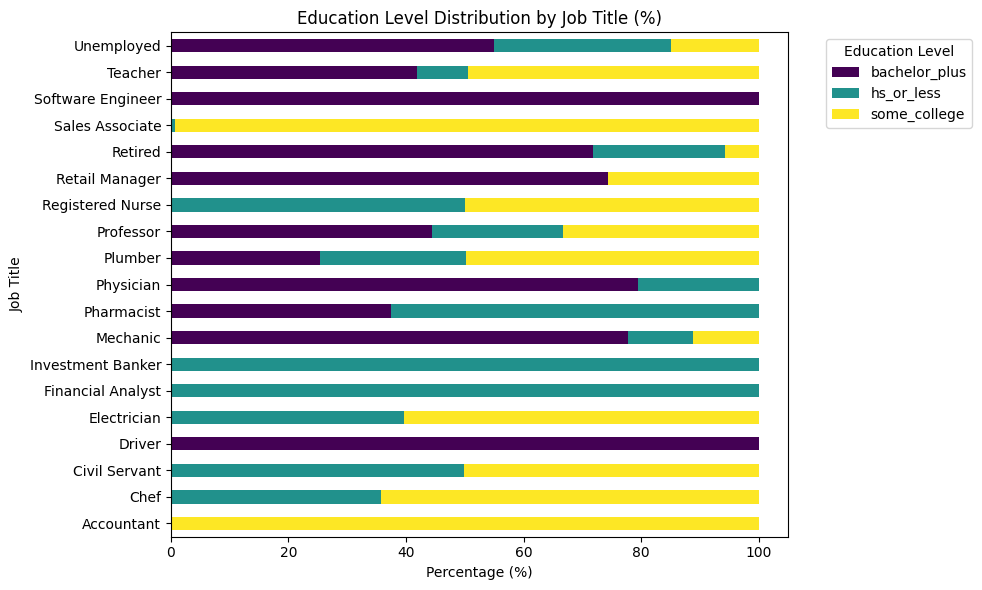

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create cross-tabulation (normalized to percentages per job)
job_edu = pd.crosstab(new['job'], new['education'], normalize='index') * 100

# 2. Plot 100% Stacked Bar Chart
job_edu.plot(kind='barh', stacked=True, figsize=(10, 6), colormap='viridis')

plt.title('Education Level Distribution by Job Title (%)')
plt.xlabel('Percentage (%)')
plt.ylabel('Job Title')
plt.legend(title='Education Level', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
